#### 복습
- LLM = 대규모 언어 모델 (언 어!!)
- 에이전트 = 특정 작업을 수행하는 주체 (모델, 도구, 실행절차를 가진 주체...)
- Tool = 에이전트가 사용하는 도구 (예: 데이터베이스, API, 파일 시스템 등)
- State = 그래프에서 전체적으로 값을 기억하고 기록하는 역할
- Node = 그래프에서 상태를 나타내는 단위(내부적으론 함수로 나타냄)
- Edge = 그래프에서 노드 간의 관계를 나타내는 단위
- 노드와 에이전트의 차이점:
    - 노드: 그래프 안에서 실행단이 1개임
        - 노드는 llm이 들어있을수도 있고 단순한 함수일 수도 있음(안들어있을수도 있다는 말)
    - 에이전트: 목표를 가지고 실행할 수 있는 시스템이고 노드를 포함할 수 있음
        - 에이전트는 무조건 llm을 가지고 있어야 함
        - 즉, 에이전트는 여러 노드를 조합하여 복잡한 작업을 수행할 수 있음

![복습이미지](./images/ref/06_01.png)

___
```Markdown - 서론
이제는 시작이 있으면 llm에게 질문을 던지고 이 llm자체가 '검색이 필요한데?'하고 검색을 할건데
이 검색하는 툴 중에(Tavli...말고도 여러개 많음) 어떤 툴을 사용할지 llm이 판단해서 검색을 수행하게 될 것임

그럼 저 검색툴도 노드로 등록되어야 있어야 했는데
에이전트를 하나 만들어서 검색 엔진을 다 집어넣어두고
하나의 특정 전문 분야들끼리 묶어 에이전트를 만들고?

그 여러 에이전트들을 = 전문가 집단을 만들어 협업하게 할 수 있음!!
```

# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움!
- Multi Agent는 작업을 역할별로 나누고, 각 결과를 다음 담당자에게 전달함~!! (전문가 집단!)
    - [Multi Agent 종류]
    - Network: 동료 간 상호 위임이 가능한 연결 구조(거미줄처럼 연결되어있음)
    - Supervisor: 여러 담당자의 순서를 결정하는 중앙 관리자(나머지 에이전트를 컨트롤하는 심판 역할)
    - Hierarchical: 팀 안에 팀이 있는 계층적인 조직(Supervisor 확장판으로, 여러 계층의 관리자가 존재함)
    - Custom: 특정 요구사항에 맞게 설계된 맞춤형 구조(내가 만들고싶은 상태로 수정해서 만드는~~ | 위 3개가 기본적인거임)


### **1-1. 용어 설명**

#### 1-1-1. HandOff
- 현재 담당자가 다른 담당자에게 실행 제어권을 넘기는 것
- 그래프상에서 에이전트가 서로 다른 경우를 말하는데, 한 에이전트가 수행하던 작업을 다른 에이전트가 이어받아 수행하게 되는 상황을 의미함.

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
# 에이전트 간 공유할 상태
class HandoffState(TypedDict, total=False):
    request: str        # 사용자 요청
    department: str     # 담당 부서
    answer: str         # 답변

# 요청 내용에 따라 담당 부서 결정
def triage(state: HandoffState):
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    return {"department": dept}

# 코딩 담당: 코드 예제 반환
def coding(state: HandoffState):
    return {"answer": f"[코딩 담당] {state['request']} > 예제: for x in [1, 2, 3]: print(x)"}

# 글쓰기 담당: 글 구성 안내 반환
def writing(state: HandoffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

# 결정된 담당 부서로 이동할 경로 반환
def route_handoff(state: HandoffState):
    return state["department"]

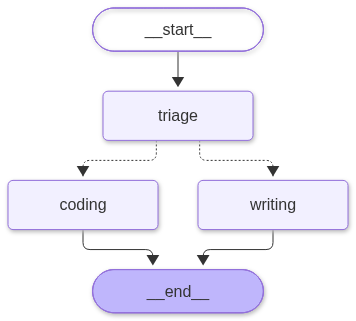

In [3]:
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

builder.add_edge(START, "triage")
builder.add_conditional_edges("triage", route_handoff, {"coding": "coding", "writing": "writing"})
builder.add_edge("coding", END)
builder.add_edge("writing", END)

handoff_graph = builder.compile()
handoff_graph

In [4]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request": q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩 담당] 파이썬 for문 설명해줘 > 예제: for x in [1, 2, 3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [5]:
# stream_mode="updates": 과정이 보임
# 근데 지금은 단일 에이전트고 멀티에이전트로 바꾸려면 아래 코드셀 확인!
for update in handoff_graph.stream({"request": "파이썬 리스트 예제"}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩 담당] 파이썬 리스트 예제 > 예제: for x in [1, 2, 3]: print(x)'}}


In [6]:
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from typing import TypedDict, Literal

In [7]:
llm = ChatOpenAI(model="gpt-5.6-luna", temperature=0)

# ★★ 1. 분류 에이전트(노드 아님!!)
# Command: 실질적으로 Handoff를 실행하는건데 (이게 이제 에이전트들과 주고받기가 가능하게 해주는거임)
# Literal: 특정 값만 허용하도록 타입 지정
def triage(state: HandoffState) -> Command[Literal["coding", "writing"]]:
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    # goto: 이동할 에이전트 지정(명령어임) -> 다음에 실행할 노드 지정과 같은 말
    # update: 공유 상태(State)에 department 정보를 저장함
    return Command(update={"department": dept}, goto=dept)


# ★★ 2. 코딩 에이전트(노드 아님!!)
def coding(state: HandoffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}


# ★★ 3. 글쓰기 에이전트(노드 아님!!)
def writing(state: HandoffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요. \n요청: {state['request']}"
    )
    return {"answer": response.content}

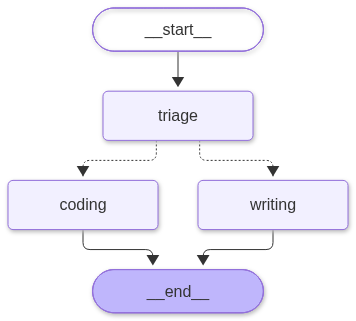

In [8]:
# 이제 위에걸로 그래프 구성!
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

# 멀티 에이전트에선 add_conditional_edges가 필요 없고, triage에서 바로 각 에이전트로 이동함(goto 사용)
builder.add_edge(START, "triage")
builder.add_edge("coding", END)
builder.add_edge("writing", END)

graph = builder.compile()
graph

In [9]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request": q})
    print(f"\n질문: {q}")
    print(f"담당: {result['department']}")
    print(f"답변: {result['answer']}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: 파이썬의 `for문`은 **여러 번 반복해서 실행할 때** 사용합니다.

## 1. 기본 형태

```python
for 변수 in 반복할_자료:
    실행할_코드
```

예를 들어 리스트의 값을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "포도"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
포도
```

동작 방식은 다음과 같습니다.

1. `fruits`에서 첫 번째 값 `"사과"`를 꺼냅니다.
2. `fruit` 변수에 저장합니다.
3. `print(fruit)`를 실행합니다.
4. 다음 값으로 넘어가 같은 작업을 반복합니다.

---

## 2. 숫자를 반복하기: `range()`

`range()`는 일정한 범위의 숫자를 만들어 줍니다.

```python
for i in range(5):
    print(i)
```

결과:

```text
0
1
2
3
4
```

주의할 점은 `range(5)`가 **0부터 4까지**라는 것입니다.  
끝 숫자인 `5`는 포함되지 않습니다.

### 시작과 끝 지정

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

형식은 다음과 같습니다.

```python
range(시작, 끝)
```

### 간격 지정

```python
for i in range(0, 10, 2):
    print(i)
```

결과:

```text
0
2
4
6
8
```

형식은 다음과 같습니다.

```python
range(시작, 끝, 간격)
```

---

## 3. 문자열도 반복할 수 있습니다

문자열의 글자를 하나씩 꺼낼 수도 있습니다.

```python
for char in "Python":
    print(char)
```

결과:

``

![에이전트와 멀티에이전트 차이](./images/ref/06_02.png)

### **1-2. 종류1) Network**
각 전문 에이전트로 되어 있으며 직접 이웃 에이전트로 handoff를 한다.

In [10]:
from tavily import TavilyClient
from dotenv import load_dotenv
from pathlib import Path
from pydantic import BaseModel, Field  # llm이 값을 줄 때 구조화시켜 줄 수 있도록 하는..
import os, json
import matplotlib.pyplot as plt

In [11]:
load_dotenv()

True

In [12]:
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError(".env 파일에 OPENAI API KEY가 설정되어 있지 않습니다.")

llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5.6-luna"), temperature=0)

In [13]:
OUTPUT_DIR = Path("multi_agent_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

[에이전트를 네트워크형식으로 구현해볼게~]

In [14]:
# llm에게 지시와 사용자 입력을 구분해서 질문 보냄
def ask(system: str, user: str) -> str:
    """시스템 지시와 사용자 입력을 구분해 LLM을 호출합니다."""
    response = llm.invoke([("system", system), ("human", user)])
    return str(response.content)

In [15]:
# 차트 상태
class ChartState(TypedDict, total=False):
    question: str
    sources: list[dict]
    data: list[dict]
    summary: str
    chart_path: str
    error: str

# 차트 데이터
class ChartData(TypedDict):
    label: str
    value: float

In [16]:
# 웹 검색 함수
def search_web(query: str) -> list[dict]:
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError(".env 파일에 TAVILY API KEY가 설정되어 있지 않습니다.")
    result = TavilyClient(api_key=key).search(query=query, max_results=5)
    return [{
        "title": x.get("title", ""), 
        "url": x.get("url", ""), 
        "content": x.get("content", "")[:1500]
    } for x in result.get("results", [])]

In [17]:
# llm이 주는 값을 구조화시킴
class ResearchData(BaseModel):
    data: list[ChartData] = Field(description="출처에서 확인된 수치만 포함!")
    summary: str

In [18]:
# 구조화된 출력이 가능한 llm 생성함
research_llm = llm.with_structured_output(ResearchData)

In [19]:
# 연구자 역할을 수행해서 검색결과 분석하고, 검증 가능한 수치 추출함
def resercher(state: ChartState) -> Command[Literal["chart", "__end__"]]:
    # 사용자 질문 기반으로 웹 검색 수행
    sources = search_web(state["question"])
    # 검색 결과에서 검증 가능한 수치를 추출
    parsed = research_llm.invoke([
        ("system", "검색 결과에 명시된 값만 추출하세요. 추정하거나 없는 수치를 생성하지 마세요. 각 수치의 단위가 일관되어야 합니다. 확인 불가능하면 data를 빈 목록으로 반환하세요."),
        ("human", json.dumps({"question": state["question"], "sources": sources}, ensure_ascii=False))
    ])

    # parsed 데이터가 없으면 에러 저장 후 종료
    if not parsed.data:
        return Command(update={
            "sources": sources,
            "error": "검증 가능한 수치가 없습니다."
        }, goto=END)
    # 그게 아니라면(데이터가 있다면)
    # 검색 결과, 수치, 요약을 저장하고 차트노드로 이동
    return Command(update={
        "sources": sources,
        "data": [x.model_dump() if hasattr(x, "model_dump") else x for x in parsed.data],
        "summary": parsed.summary
    }, goto="chart")

In [20]:
def chart(state: ChartState) -> Command[Literal["__end__"]]:
    rows = state["data"]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar([r["label"] for r in rows], [r["value"] for r in rows])
    ax.set_title("Research results (verify units and sources)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    path = OUTPUT_DIR / "research_chart.png"
    fig.savefig(path, dpi=140)
    plt.show()
    plt.close(fig)
    return Command(update={"chart_path":str(path)}, goto=END)

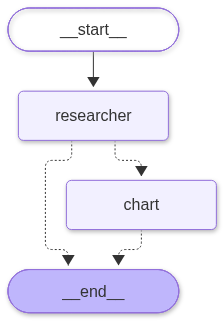

In [21]:
builder = StateGraph(ChartState)

builder.add_node("researcher", resercher)
builder.add_node("chart", chart)
# END를 쓸 필요가 없음
# why?! 
# 위에서 Command(goto=END)를 사용했으니까 여기서 END 정의 안해도됨 쩐다!!

builder.add_edge(START, "researcher")
network_chart = builder.compile()
network_chart

In [22]:
# 맷플로립 한글깨짐 방지
import matplotlib as mpl

# 한글 폰트 설정 (Windows)
mpl.rcParams["font.family"] = "Malgun Gothic"
# 마이너스(-) 기호 깨짐 방지
mpl.rcParams["axes.unicode_minus"] = False

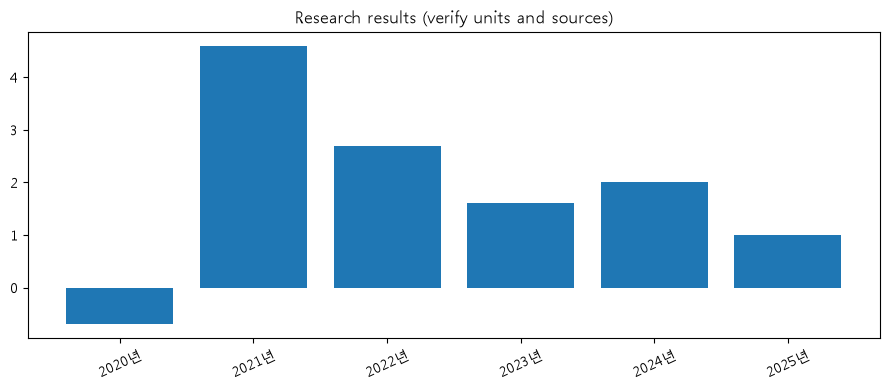

In [23]:
result = network_chart.invoke(
    {"question": "2020년부터 2025년까지 한국의 연도별 실질 GDP 성장률(%)"}, 
    config={"recursion_limit": 5}
)

#### 2-1-1. 실습) 멀티 에이전트 기반(Network) AI 맞춤형 학습 진단 및 문제 출제 시스템
학생의 과목별 학습 점수를 분석해 가장 취약한 학습 영역을 찾아내고, 해당 영역에 대한 맞춤형 문제를 자동으로 출제하는 AI 학습 진단 멀티 에이전트 시스템 개발해보기

- Diagnosis Agent: 학생의 영역별 점수를 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성
- Quiz Agent: 진단 결과를 받아 취약 영역에 대한 객관식 문제 생상

```
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}

1. 학생의 학습 점수를 입력받음
2. 모든 점수가 0~100점 사이인지 검사
3. 가장 점수가 낮은 학습 영역을 찾음
4. llm을 이용해 학생의 학습 상태를 3문장으로 진단
5. 진단 결과를 문제 출제 에이전트에게 전달
6. llm을 이용해 취약 영역에 대한 객관식 문제 3개를 생성
7. 각 문제에 정답과 해설을 포함
8. 최종 진단 결과와 생성된 문제를 출력
```

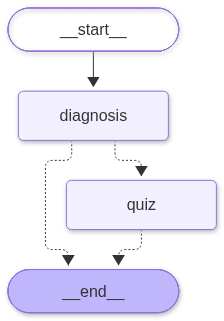

In [24]:
# 에이전트들이 공유할거
class StudyStatemy(TypedDict, total=False):
    scores: dict[str, int]
    down_subject: str
    diagnosis: str
    quiz_ss: list[dict]
    error: str


# 첫번째 에이전트: Diagnosis Agent
def diagnosismy(state: StudyStatemy) -> Command[Literal["quiz", "__end__"]]:
    # 1단계) 과목별 점수 가져옴
    scores = state["scores"]
    # 2단계) 점수 검사(0~100점)
    if not scores or any(
        type(score) not in (int, float) or not 0 <= score <= 100
        for score in scores.values()
    ):
        return Command(
            update={"error": "점수는 0~100 사이여야 합니다."}, goto=END
        )
    # 3단계) 가장 점수 낮은애
    down_subject = min(scores, key=scores.get)
    # 4단계) llm 이용해서 3문장 진단하기
    response = llm.invoke([
        ("system", "학습 진단 전문가가 되어 학생의 과목별 점수를 분석하고 학습 상태를 3문장으로 진단하세요."),
        ("human", f"과목별 점수: {scores} | 취약 과목: {down_subject}")
    ])
    # 5단계) 결과 문제 출제 에이전트에 전달하기
    return Command(
        update={
            "down_subject": down_subject,
            "diagnosis": str(response.content)
        }, goto="quiz"
    )

# 객관식 문제 하나의 구조 정의 -> 이것도 해야지!!
class QuizDatamy(TypedDict):
    question: str
    options: list[str]
    answer: int
    explanation: str

# llm이 주는 값 구조화 시키기
class ResearchQuizmy(BaseModel):
    # quiz_ss: list[dict[str, str]] 이걸 이렇게 쓰면 안돼고..아래처럼 써야지!!
    quiz_ss: list[QuizDatamy] = Field(
        description="취약 과목에 대한 객관식 4지선다 문제 3개와 각 문제의 정답 번호, 해설"
    )

# llm 생성
quiz_llm = llm.with_structured_output(ResearchQuizmy)

# 두번째 에이전트 Quiz Agent
def quiz(state: StudyStatemy) -> Command[Literal["__end__"]]:
    # 첫번째 에이전트가 전달한 결과 받아옴
    down_subject = state["down_subject"]
    diagnosis = state["diagnosis"]
    # 6단계 + 7단계) llm 이용해서 문제 만듦
    parsed = quiz_llm.invoke([
        ("system", "학습 문제 출제 전문가가 되어 학생의 취약 과목과 학습 진단 결과를 합고해 객관식 4지선다 문제를 3개 생성하세요. 문제는 정답과 해설을 포함하세요."),
        ("human", f"취약 과목: {down_subject} | 진단: {diagnosis}")
    ])
    # 문제 출제 끝. 그래프 종료
    return Command(
        update={"quiz_ss": parsed.quiz_ss}, goto=END
    )


# 이제 그래프 그려
mybuilder = StateGraph(StudyStatemy)

mybuilder.add_node("diagnosis", diagnosismy)
mybuilder.add_node("quiz", quiz)

mybuilder.add_edge(START, "diagnosis")

my_graph = mybuilder.compile()
my_graph

In [25]:
# 이제 실행해보자
scores = {
    "파이썬 기초문법": 90,
    "데이터 분석": 75,
    "딥러닝": 60
}

result = my_graph.invoke({"scores": scores})
result

{'scores': {'파이썬 기초문법': 90, '데이터 분석': 75, '딥러닝': 60},
 'down_subject': '딥러닝',
 'diagnosis': '파이썬 기초문법은 90점으로 매우 탄탄하며, 데이터 분석은 75점으로 기본기는 있으나 응용력 보완이 필요합니다.  \n딥러닝은 60점으로 가장 취약하며, 핵심 개념과 모델 구조·학습 과정에 대한 이해가 부족한 상태로 진단됩니다.  \n우선 딥러닝의 기초 이론과 실습을 집중 학습하고, 데이터 분석 역량을 함께 강화하면 전반적인 성취도 향상에 도움이 됩니다.',
 'quiz_ss': [{'question': '딥러닝에서 여러 층의 인공 신경망을 학습시키기 위해 각 가중치의 손실 함수에 대한 기울기를 계산하는 알고리즘은 무엇인가요?',
   'options': ['순전파', '역전파', '정규화', '원-핫 인코딩'],
   'answer': 2,
   'explanation': '역전파는 출력층에서 계산된 손실을 이전 층으로 전달하면서 각 가중치에 대한 기울기를 계산하는 과정입니다. 이후 경사 하강법 등을 사용해 가중치를 업데이트합니다.'},
  {'question': '다음 중 은닉층에서 ReLU 활성화 함수를 사용하는 주된 이유로 가장 적절한 것은 무엇인가요?',
   'options': ['출력값을 항상 0과 1 사이로 제한하기 위해',
    '음수 입력을 그대로 유지하고 양수 입력만 제곱하기 위해',
    '비선형성을 추가하고 기울기 소실 문제를 완화하기 위해',
    '모든 뉴런의 가중치를 동일하게 만들기 위해'],
   'answer': 3,
   'explanation': 'ReLU 함수는 입력이 0보다 크면 입력값을 출력하고, 0보다 작으면 0을 출력합니다. 비선형성을 제공하면서 시그모이드 함수보다 기울기 소실 문제를 비교적 줄일 수 있어 은닉층에서 널리 사용됩니다.'},
  {'question': '딥러닝 모델이 훈련 데이터에서는 매우 높은 정확도를 보이지만, 새로운 검증 데이터

In [26]:
# 검증도 - GPT도움
if result.get("error"):
    print("오류:", result["error"])

else:
    print("===== 학습 진단 =====")
    print("취약 과목:", result["down_subject"])
    print("진단:", result["diagnosis"])

    print("\n===== 객관식 문제 =====")

    for i, q in enumerate(result["quiz_ss"], start=1):
        print(f"\n문제 {i}. {q['question']}")

        for j, option in enumerate(q["options"], start=1):
            print(f"{j}. {option}")

        print(f"정답: {q['answer']}번")
        print(f"해설: {q['explanation']}")

===== 학습 진단 =====
취약 과목: 딥러닝
진단: 파이썬 기초문법은 90점으로 매우 탄탄하며, 데이터 분석은 75점으로 기본기는 있으나 응용력 보완이 필요합니다.  
딥러닝은 60점으로 가장 취약하며, 핵심 개념과 모델 구조·학습 과정에 대한 이해가 부족한 상태로 진단됩니다.  
우선 딥러닝의 기초 이론과 실습을 집중 학습하고, 데이터 분석 역량을 함께 강화하면 전반적인 성취도 향상에 도움이 됩니다.

===== 객관식 문제 =====

문제 1. 딥러닝에서 여러 층의 인공 신경망을 학습시키기 위해 각 가중치의 손실 함수에 대한 기울기를 계산하는 알고리즘은 무엇인가요?
1. 순전파
2. 역전파
3. 정규화
4. 원-핫 인코딩
정답: 2번
해설: 역전파는 출력층에서 계산된 손실을 이전 층으로 전달하면서 각 가중치에 대한 기울기를 계산하는 과정입니다. 이후 경사 하강법 등을 사용해 가중치를 업데이트합니다.

문제 2. 다음 중 은닉층에서 ReLU 활성화 함수를 사용하는 주된 이유로 가장 적절한 것은 무엇인가요?
1. 출력값을 항상 0과 1 사이로 제한하기 위해
2. 음수 입력을 그대로 유지하고 양수 입력만 제곱하기 위해
3. 비선형성을 추가하고 기울기 소실 문제를 완화하기 위해
4. 모든 뉴런의 가중치를 동일하게 만들기 위해
정답: 3번
해설: ReLU 함수는 입력이 0보다 크면 입력값을 출력하고, 0보다 작으면 0을 출력합니다. 비선형성을 제공하면서 시그모이드 함수보다 기울기 소실 문제를 비교적 줄일 수 있어 은닉층에서 널리 사용됩니다.

문제 3. 딥러닝 모델이 훈련 데이터에서는 매우 높은 정확도를 보이지만, 새로운 검증 데이터에서는 낮은 정확도를 보이는 현상은 무엇이며, 이를 완화하는 방법으로 적절한 것은 무엇인가요?
1. 과적합이며, 드롭아웃이나 데이터 증강을 사용할 수 있다.
2. 과소적합이며, 모델의 층 수를 줄여야 한다.
3. 기울기 폭발이며, 학습률을 항상 0으로 설정해야 한다.
4. 정규화이며, 훈련 데이터를 삭제해야 한다.
정답: 1번


이 아래가 강사님 코드!!

In [27]:
class StudyState(TypedDict, total=False):
    scores: dict[str, int]
    weakness: str
    diagnosis: str
    quiz: str

def diagnosis(state: StudyState) -> Command[Literal["quiz"]]:
    scores = state["scores"]
    if not scores or any(not 0 <= v <= 100 for v in scores.values()):
        raise ValueError("영역별 점수를 0~100 사이로 입력하세요")
    weak = min(scores, key=scores.get)
    explanation = ask(
        "당신은 친절한 학습 진단 전문가입니다. 점수의 의미를 과장하지 말고 3문장으로 분석하세요", 
        f"영역별 점수: {scores}, 취약 과목: {weak}"
    )
    return Command(update={"weakness": weak, "diagnosis": explanation}, goto="quiz")

def quiz(state: StudyState) -> Command[Literal["__end__"]]:
    content = ask(
        "당신은 학습문제 출제 전문가입니다. 지정된 취약 과목에 대해 객관식 3문제를 만들고 각 문항에 정답과 쉬운 해설을 붙이세요. 애매한 문항은 피하세요.",
        f"취약 과목: {state['weakness']} | 진단: {state['diagnosis']}"
    )
    return Command(update={"quiz": content}, goto=END)

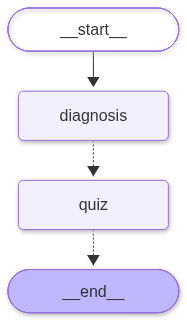

In [28]:
builder = StateGraph(StudyState)
builder.add_node("diagnosis", diagnosis)
builder.add_node("quiz", quiz)
builder.add_edge(START, "diagnosis")
study_network = builder.compile()
study_network

In [29]:
result = study_network.invoke(
    {"scores": {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}},
    config={"recursion_limit": 5}
)

In [30]:
print("[진단]", result["diagnosis"], "\n[문제]", result["quiz"])

[진단] 파이썬 기초문법은 90점으로 기본기가 비교적 탄탄하고, 데이터 분석은 75점으로 핵심 개념을 어느 정도 이해하고 있습니다.  
딥러닝은 60점으로 다른 영역보다 보완이 필요하지만, 점수만으로 학습 능력을 단정하기보다는 기초 수학·모델 구조·실습 경험 중 부족한 부분을 확인하는 것이 좋습니다.  
먼저 신경망의 기본 원리와 손실 함수·역전파를 복습한 뒤, 간단한 모델을 직접 구현하며 데이터 분석과 연결해 학습해 보세요. 
[문제] ## 딥러닝 객관식 문제 3문제

### 1번. 신경망의 순전파 계산

입력값이 \(x_1=2\), \(x_2=1\)이고, 가중치가 \(w_1=0.5\), \(w_2=1\), 편향이 \(b=-1\)일 때 다음 뉴런의 출력값은 얼마인가?

\[
z=w_1x_1+w_2x_2+b
\]

활성화 함수는 ReLU를 사용한다.

\[
\text{ReLU}(z)=\max(0,z)
\]

① 0  
② 0.5  
③ 1  
④ 2  

**정답: ③ 1**

**해설:**  
먼저 가중합을 계산하면 다음과 같습니다.

\[
z=(0.5\times2)+(1\times1)-1=1
\]

ReLU 함수는 양수를 그대로 출력하므로 최종 출력은 **1**입니다.

---

### 2번. 손실 함수의 의미

실제 정답이 \(y=1\)인 이진 분류 문제에서 다음 두 예측 중 일반적으로 더 작은 손실을 만드는 예측은 무엇인가?

① 예측 확률 \(p=0.1\)  
② 예측 확률 \(p=0.4\)  
③ 예측 확률 \(p=0.6\)  
④ 예측 확률 \(p=0.9\)  

**정답: ④ 예측 확률 \(p=0.9\)**

**해설:**  
실제 정답이 1이면 모델은 1에 가까운 확률을 예측할수록 잘한 것입니다.  
따라서 \(p=0.9\)가 \(p=0.1, 0.4, 0.6\)보다 정답에 가까워 손실이 더 작습니다. 손실 함수는 **모델의 예측과 실제 정답의 차이**를 나타냅니다.

---

### 3번. 경사하강법을 이용한 가중치 업데이트

현재 가중치가 \

### **1-3. 종류2) Supervisor**
Supervisor가 여러 전문 에이전트에게 작업을 순서대로 맡기고, 모든 작업이 끝나면 결과를 반환하는 구조

In [31]:
# total=False : 이 안에 있는 모든 데이터가 다 채워질 필요 없다는 뜻
class TripState(TypedDict, total=False):
    request: str             # 사용자의 여행 요청
    sources: list[dict]      # 웹 검색 결과
    research: str            # 조사 에이전트가 작성한 요약
    recommendation: str      # 추천 에이전트가 작성한 결과
    saved_path: str          # 저장된 파일 경로
    next_step: str           # LLM이 선택한 다음 작업
    error: str               # 오류 정보를 기록하기 위한 필드

class RouterDecision(BaseModel):
    next_step: Literal["search_agent", "recommendation_agent", "save_agent", "FINISH"]

In [32]:
router_llm = llm.with_structured_output(RouterDecision)

#### 아래 코드 설명 가지뻗기
- next함수란? 조건함수로 True가 되는 첫 번째 값을 반환하는 함수
- iter함수란? 반복 가능한 객체를 반환하는 함수, 여기선 dict_items를 반복 가능하게 만들어줌
- 그럼 이터러블과 이터레이터의 차이는?
- 이터러블은 반복 가능한 객체이고, 이터레이터는 실제로 반복을 수행하는 객체

```
이터로 감싸면 이러터블이 이터레이터로 변환!
그럼 이게 데이터 순서를 가지니까 반복할 때 순서대로 값을 가져올 수 있는거임
```

In [33]:
# 여행 상태 확인하고 다음에 수행할 에이전트 결정
def supervisor(state: TripState) -> Command[Literal["search_agent", "recommend_agent", "save_agent", "__end__"]]:
    completed = {
        "search_agent": bool(state.get("research")),
        "recommend_agent": bool(state.get("recommendation")),
        "save_agent": bool(state.get("saved_path"))
    }

    # all: 모두 다 참일때만 다음 단계로 진행(지금 코드에선 END로 보내게 됨)
    if all(completed.values()):
        return Command(goto=END)

    # 여행 감독자에게 다음 수행할 작업을 결정하도록 요청
    decision = router_llm.invoke([
        ("system", "당신은 여행 작업 감독자입니다. 반드시 검색, 추천, 저장 순서로 진행하세요. 이미 완료한 작업은 반복하지 마세요. 다음 작업 이름만 선택하세요."),
        ("human", json.dumps({"request": state["request"], "completed": completed}, ensure_ascii=False))
    ])

    # 다음 수행할 작업을 결정한 후, 아직 완료되지 않은 첫 번째 작업을 expected로 설정
    expected = next(k for k, v in completed.items() if not v)

    return Command(update={"next_step": decision.next_step}, goto=expected)

In [34]:
# 여행 조사원 에이전트
def trip_search(state: TripState) -> Command[Literal["supervisor"]]:
    sources = search_web(state["request"] + "여행 추천 관광지 날씨 예보")
    text = ask(
        "여행 조사원입니다. 출처에 근거한 내용만 요약하고 날짜가 확인되지 않은 날씨는 확정하지 마세요.", 
        json.dumps(sources, ensure_ascii=False)
    )
    return Command(update={"sources": sources, "research": text}, goto="supervisor")

# 추천 전문가 에이전트
def trip_recommend(state: TripState) -> Command[Literal["supervisor"]]:
    text = ask(
        "여행 추천 전문가입니다. 조사 내용을 바탕으로 여행지 3곳과 이유, 날씨 확인 주의사항을 작성하세요. 검증되지 않은 운영시간, 예보는 쓰지 마세요.", 
        state["request"]+"\n"+state["research"]
    )
    return Command(update={"recommendation": text}, goto="supervisor")

# 여행 저장 담당자 에이전트
def trip_save(state: TripState) -> Command[Literal["supervisor"]]:
    path = OUTPUT_DIR / "trip_recommendation.md"
    refs = "\n".join("-"+s["url"] for s in state.get("sources", []))
    path.write_text(
        "# 여행 추천\n\n" + state["recommendation"] + 
        "\n\n### 참고 검색 링크(출처)\n\n" + refs, 
        encoding="utf-8"
    )
    return Command(update={"saved_path": str(path)}, goto="supervisor")

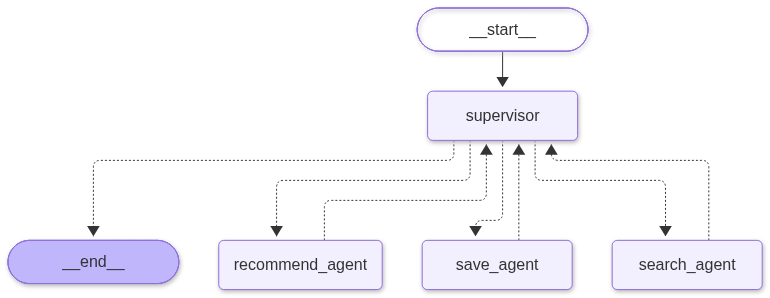

In [35]:
# 이제 그래프 만들기
builder = StateGraph(TripState)

# for문으로 돌면서 node 생성하기
for name, fn in [
    ("supervisor", supervisor),
    ("search_agent", trip_search),
    ("recommend_agent", trip_recommend),
    ("save_agent", trip_save)
]:
    builder.add_node(name, fn)

# edge는 하나만 걸면 됨
builder.add_edge(START, "supervisor")

trip_graph = builder.compile()
trip_graph

In [36]:
result = trip_graph.invoke({"request": "제주도 2박 3일 자연 경관 중심 여행지를 추천해줘"}, config={"recursion_limit": 10})

In [37]:
# result
print(result["recommendation"])
print("저장파일:", result["saved_path"])

## 제주도 2박 3일 자연경관 중심 추천 여행지 3곳

### 1. 성산일출봉·섭지코지 일대 — 제주 동부
**추천 이유**
- 성산일출봉의 화산 지형과 성산 앞바다 전망을 한 번에 볼 수 있습니다.
- 섭지코지는 해안 산책로와 초지, 바위 해안이 이어져 가벼운 산책에 적합합니다.
- 일출 명소를 포함한 동부 대표 자연경관으로, 제주에 처음 방문할 때 넣기 좋습니다.

**추천 일정**
- 1일 차: 성산일출봉 → 섭지코지 → 성산·표선권 숙박
- 성산일출봉 정상 등반이 부담스럽다면 주변 전망과 해안 산책 중심으로 조정할 수 있습니다.

**주의사항**
- 성산일출봉 등반 가능 여부와 탐방로 통제는 방문 당일 공식 안내를 확인하세요.
- 바람이 강한 날에는 섭지코지 해안 가장자리 접근을 피하는 것이 좋습니다.

---

### 2. 주상절리대·중문 해안 — 제주 남부
**추천 이유**
- 육각형 기둥 모양의 주상절리와 거친 해안 지형을 볼 수 있는 대표적인 지질 경관입니다.
- 중문 일대에 관광지가 밀집해 있어 이동 부담이 비교적 적습니다.
- 해안 산책과 서귀포권 숙박을 함께 구성하기 좋습니다.

**추천 일정**
- 2일 차: 중문 주상절리대 → 중문 해안 산책 → 서귀포권 숙박
- 체력과 날씨에 따라 천지연폭포나 외돌개 등 서귀포 주변 자연 명소를 추가할 수 있습니다.

**주의사항**
- 파도가 높거나 강풍이 불면 해안 전망 구간이 미끄러울 수 있습니다.
- 해안 산책로와 전망시설의 통제 여부는 출발 전 공식 채널에서 확인하세요.

---

### 3. 협재·금능 해변 및 한림권 — 제주 서부
**추천 이유**
- 맑은 바다와 백사장, 비양도 조망을 함께 즐길 수 있습니다.
- 경사가 비교적 완만한 해안 산책을 구성하기 좋아 마지막 날 일정에 적합합니다.
- 공항으로 이동하기 전 서부 해안을 둘러보기에도 편리한 편입니다.

**추천 일정**
- 3일 차: 협재해변 또는 금능해변 → 한림권 해안도로 → 공항
- 비행기 출발 시간이 이르다면 해변 한 곳만

### **1-4. 종류3) Hierarchical**
- 팀 내부에 여러 작업 노드를 두고, 각 팀을 독립적인 SubGraph로 구성하는 구조
- 계층형 멀티 에이전트
```
각각의 서브그래프를 만들어서..~
필요할 때 연결해서 쓰는!

위에 슈퍼바이저 에이전트를 여러개 둔거라 생각하면 쉬움
```

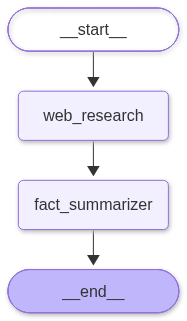

In [38]:
# [싱글 에이전트 1]
class ResearchTeamState(TypedDict, total=False):
    topic: str              # 조사항 주제
    sources: list[dict]     # 조사(웹) 검색 결과
    notes: str              # 검색 결과를 요약한 조사 노트


def find_sources(s: ResearchTeamState):
    return {"sources": search_web(s["topic"])}

def summarize_sources(s: ResearchTeamState):
    return {"notes": ask("당신은 조사전문가입니다. 제공된 검색 결과만 바탕으로 핵심 사실을 요약하고 불확실한 부분은 표시하세요.", json.dumps(s["sources"], ensure_ascii=False))}


research_builder = StateGraph(ResearchTeamState)

research_builder.add_node("web_research", find_sources)
research_builder.add_node("fact_summarizer", summarize_sources)

research_builder.add_edge(START, "web_research")
research_builder.add_edge("web_research", "fact_summarizer")
research_builder.add_edge("fact_summarizer", END)

research_team = research_builder.compile()
research_team

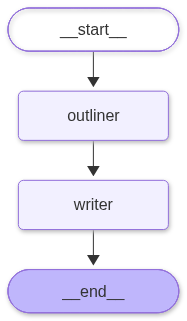

In [39]:
# [싱글 에이전트 2]
class WritingTeamState(TypedDict, total=False):
    topic: str      # 보고서 주제
    notes: str      # 조사팀에서 작성한 조사 노트
    outline: str    # 보고서 목차 및 개요
    report: str     # 최종 보고서 


def outline_writer(s: WritingTeamState):
    return {"outline": ask("당신은 문서 기획자입니다. 조사 노트만을 활용하여 제목과 3~4개 소제목으로 개요를 만드세요.", s["topic"]+"\n"+s["notes"])}

def report_writer(s: WritingTeamState):
    return {"report": ask("당신은 보고서 작성 전문가입니다. 개요와 조사 노트만을 사용하여 한국어 마크다운 보고서를 작성하세요. 불확실한 정보는 불확실하다고 표시하세요.", json.dumps(s, ensure_ascii=False))}


writing_builder = StateGraph(WritingTeamState)

writing_builder.add_node("outliner", outline_writer)
writing_builder.add_node("writer", report_writer)

writing_builder.add_edge(START, "outliner")
writing_builder.add_edge("outliner", "writer")
writing_builder.add_edge("writer", END)

writing_team = writing_builder.compile()
writing_team

In [40]:
# [이제 두 에이전트를 엮어서 사용]
class TopState(TypedDict, total=False):
    topic: str
    notes: str
    sources: list[dict]
    outline: str
    report: str
    saved_path: str

class TeamChoice(BaseModel):
    team: Literal["research_team", "writing_team", "FINISH"]

top_router = llm.with_structured_output(TeamChoice)

# 상위 감독자 및 팀 실행 함수 정의
def top_supervisor(s: TopState) -> Command[Literal["research_team", "writing_team", "__end__"]]:
    if s.get("report"):
        return Command(goto=END)
    choice = top_router.invoke([
        ("system", "상위 감독자입니다. 조사 노트가 없으면 research_team, 조사 노트가 있고 보고서가 없으면 writing_team을 선택하세요."),
        ("human", json.dumps({"topic": s["topic"], "has_notes": bool(s.get("notes")), "has_report": bool(s.get("report"))}, ensure_ascii=False))
    ])
    expected = "writing_team" if s.get("notes") else "research_team"
    return Command(goto=expected)

# 조사팀 실행 함수 정의
def run_research(s: TopState) -> Command[Literal["top_supervisor"]]:
    out = research_team.invoke({"topic": s["topic"]}, config={"recursion_limit": 10})
    return Command(update={"notes": out["notes"], "sources": out["sources"]}, goto="top_supervisor")

# 작성팀 실행 함수 정의
def run_writing(s: TopState) -> Command[Literal["top_supervisor"]]:
    out = writing_team.invoke({"topic": s["topic"], "notes": s["notes"]}, config={"recursion_limit": 10})
    path = OUTPUT_DIR / "agent_report.md"
    refs = "\n".join("- " + x["url"] for x in s["sources"])
    path.write_text(out["report"] + "\n\n### 검색 출처\n" + refs, encoding="utf-8")
    return Command(update={"outline": out["outline"], "report": out["report"], "saved_path": str(path)}, goto="top_supervisor")

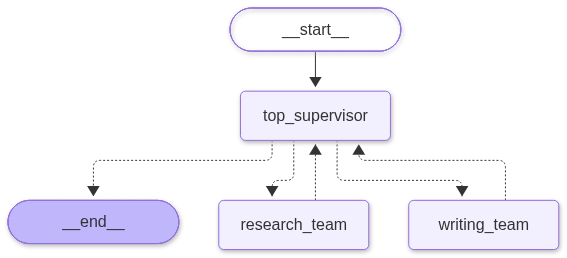

In [41]:
top_builder = StateGraph(TopState)

top_builder.add_node("top_supervisor", top_supervisor)
top_builder.add_node("research_team", run_research)
top_builder.add_node("writing_team", run_writing)

top_builder.add_edge(START, "top_supervisor")

hierarchical_graph = top_builder.compile()
hierarchical_graph

In [42]:
result = hierarchical_graph.invoke({"topic": "멀티 에이전트 시스템의 개념과 실제 활용 사례"}, config={"recursion_limit": 10})

print(result["report"])
print("보고서 저장 경로:", result["saved_path"])

# 멀티 에이전트 시스템의 개념과 실제 활용 사례

## 1. 멀티 에이전트 시스템의 개념과 핵심 구성

멀티 에이전트 시스템(Multi-Agent System, MAS)은 **여러 AI 에이전트가 각자의 전문 역할을 수행하고, 정보를 주고받으며, 협력과 조정을 통해 공동 목표를 달성하는 구조**다.

단순히 여러 개의 AI를 동시에 배치하는 것만으로는 MAS라고 보기 어렵다. 시스템으로 기능하려면 다음과 같은 요소가 함께 설계되어야 한다.

- 에이전트별 역할과 전문성
- 에이전트 간 통신 방식
- 업무 분담 및 핸드오프 절차
- 의사결정 방식과 상태 관리
- 의견 충돌 및 경쟁 상황의 조정
- 개별 결과를 전체 목표에 맞게 통합하는 방식

따라서 MAS의 핵심은 에이전트의 개수보다 **에이전트 간 관계와 협업 구조**에 있다. 전문화된 에이전트들이 서로 어떻게 정보를 전달하고, 업무를 나누며, 최종 결과를 통합하는지가 시스템의 성능을 좌우한다.

## 2. 멀티 에이전트 시스템의 작동 방식

### 2.1 업무 분할과 전문 역할 수행

일반적인 MAS는 하나의 복잡한 업무를 여러 개의 전문 작업으로 나누어 처리한다. 각 에이전트는 특정 업무나 도메인에 집중하고, 다른 에이전트의 결과를 활용해 다음 작업을 수행한다.

예를 들어 고객 지원 업무는 다음과 같이 구성할 수 있다.

1. 접수 에이전트가 고객의 초기 문의를 확인한다.
2. 검색 에이전트가 관련 문서와 정보를 찾는다.
3. 답변 생성 에이전트가 고객에게 전달할 내용을 작성한다.
4. 필요한 경우 결제 조정 또는 환불 에이전트가 후속 업무를 수행한다.
5. 해결이 어려운 사안은 담당자에게 에스컬레이션한다.

이와 같은 구조에서는 하나의 에이전트가 모든 과정을 처리하는 대신, 업무를 기능별로 나누어 처리할 수 있다.

### 2.2 핸드오프와 오케스트레이션

MAS의 업무 전달 방식은 크게 다음과 같이 구분할 수 있다.

- **핸드오프 방식:** 한 에이전트가 작업을 수행한 뒤 결과와 다음 업무를 다

___
# **2. 종합 문제**

### **2-1. AI 소프트웨어 개발팀 구축**
- Hierachical 멀티 에이전트 구조로 직접 설계하고 구현
- AI 기반 소프트웨어 개발 자동화 서비스를 만드는 개발자
```
    학생 성적 관리 프로그램을 만들어줘. 학생 이름과 점수를 등록할 수 있고, 전체 학생 목록 조회, 평균 점수 계산, 최고 점수 학생 조회 기능이 필요해
```
- 기존의 단일 LLM 시스템은 이 요청을 받아 한 번에 코드를 생성(X) 
    - 기획팀: 사용자 요구사항을 분석하고 프로그램의 구조를 설계
    - 개발팀: 설계서를 바탕으로 Python 코드를 작성하고 품질을 검토
    - 상위 감독자: 기획팀과 개발팀의 작업 순서를 관리하고 최종 결과물을 완성

### **2-2. 요구 사항**
1. Top Supervisor
- 전체 프로젝트 진행을 관리하는 상위 감독자를 구현
- 현재 State를 확인하고 아래 규칙에 따라 작업을 배정
    - 설계서가 없다면 planning_team 실행
    - 설계서가 있고, 코드가 없다면 development_team 실행
    - 코드가 있고, 검토를 통과했다면 END
    - 코드 검토에 실패했다면 개발팀에 수정 요청

2. planning Team
- 기획팀 작업 순서 결정 노드
- 사용자 요구사항 분석 노드
- 함수, 자료구조, 프로그램 구조 설계 노드
- 기획팀의 최종 출력에는 아래 내용이 포함되어야 함
    - 프로젝트 목적
    - 필수 기능 목록
    - 사용할 자료구조
    - 함수 목록 및 함수별 역할
    - 예외 처리 요구사항

3. Development Team
- 개발 작업 순서 및 재작업 관리 노드
- 설계서 기반 Python 코드 작성
- 코드 품질 및 요구사항 충족 여부 검토
    - 필수 기능이 모두 구현되었는지
    - 문법적으로 올바른 Python 코드인지
    - 함수가 적절하게 분리되었는지
    - 예외 상황이 처리되었는지
    - 코드의 가독성이 적절한지